# TGE Polymarket pilot backtest

## 1. Research question

Should an investor participate in a public token sale when point-in-time Polymarket information implies a materially higher post-TGE FDV than the sale FDV?

This notebook is a transparent pilot, not a production trading system. It keeps actionable and predictive-only projects separate, treats resolved Polymarket brackets as outcomes rather than features, and never silently substitutes proxy observations for exact values.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython import get_ipython
from IPython.display import display

get_ipython().run_line_magic("matplotlib", "inline")

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
if not (ROOT / "data" / "raw").exists():
    raise FileNotFoundError("Run the notebook from the repository root or notebooks directory.")

sys.path.insert(0, str(ROOT / "src"))
from edge_radar.tge_backtest import build_analysis_frame, filter_actionable

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.style.use("seaborn-v0_8-whitegrid")

RAW_PATH = ROOT / "data" / "raw" / "tge_polymarket_pilot_2025_2026.csv"
PROCESSED_PATH = ROOT / "data" / "processed" / "tge_polymarket_backtest_v0.csv"


## 2. Dataset loading

The raw CSV is loaded without modification. The notebook writes only a derived, explicitly labeled table under `data/processed/`.


In [2]:
raw = pd.read_csv(RAW_PATH)

assert raw["project"].notna().all()
assert raw["token"].notna().all()
assert raw.duplicated(["project", "token"]).sum() == 0
assert set(raw["pm_actionability"]) == {"actionable", "predictive_only"}

print(f"Raw dataset: {raw.shape[0]} projects × {raw.shape[1]} columns")
print(f"Duplicate project/token rows: {raw.duplicated(['project', 'token']).sum()}")
display(raw[["project", "token", "sale_platform", "pm_actionability"]])


Raw dataset: 10 projects × 61 columns
Duplicate project/token rows: 0


,project,token,sale_platform,pm_actionability
0,Pump.fun,PUMP,Kraken / public sale,actionable
1,Plasma,XPL,Plasma public sale,actionable
2,Monad,MON,Coinbase Token Sales,actionable
3,tea Protocol,TEA,CoinList,predictive_only
4,Flying Tulip,FT,CoinList,actionable
5,Solstice,SLX,Legion,actionable
6,Zama,ZAMA,CoinList,predictive_only
7,Immunefi,IMU,CoinList,predictive_only
8,Aztec,AZTEC,CoinList,actionable
9,Ranger,RNGR,MetaDAO,actionable


## 3. Data-quality audit

Missing values remain missing. They are not converted to zero. The audit focuses on fields needed for a point-in-time signal, outcome measurement, benchmarks and historical social controls.


In [3]:
audit_fields = [
    "pm_pre_tge_snapshot_time_utc",
    "pm_pre_tge_probs",
    "pm_probs_proxy",
    "price_1d_usd",
    "price_1d_proxy_usd",
    "price_7d_usd",
    "price_30d_usd",
    "price_90d_usd",
    "twitter_score_pre_tge",
    "followers_pre_tge",
    "followers_growth_30d",
    "btc_return_1d_pct",
    "eth_return_1d_pct",
]

missing_audit = pd.DataFrame({
    "field": audit_fields,
    "available": [int(raw[field].notna().sum()) for field in audit_fields],
    "missing": [int(raw[field].isna().sum()) for field in audit_fields],
})
missing_audit["coverage_pct"] = 100 * missing_audit["available"] / len(raw)
display(missing_audit)

all_empty = [field for field in raw.columns if raw[field].isna().all()]
print(f"Completely empty fields ({len(all_empty)}):")
print(", ".join(all_empty))


,field,available,missing,coverage_pct
0,pm_pre_tge_snapshot_time_utc,0,10,0.0
1,pm_pre_tge_probs,0,10,0.0
2,pm_probs_proxy,3,7,30.0
3,price_1d_usd,6,4,60.0
4,price_1d_proxy_usd,3,7,30.0
5,price_7d_usd,3,7,30.0
6,price_30d_usd,4,6,40.0
7,price_90d_usd,4,6,40.0
8,twitter_score_pre_tge,0,10,0.0
9,followers_pre_tge,0,10,0.0


Completely empty fields (13):
pm_pre_tge_snapshot_time_utc, pm_pre_tge_probs, twitter_score_pre_tge, followers_pre_tge, followers_growth_30d, btc_return_1d_pct, btc_return_7d_pct, btc_return_30d_pct, btc_return_90d_pct, eth_return_1d_pct, eth_return_7d_pct, eth_return_30d_pct, eth_return_90d_pct


In [4]:
quality_audit = pd.DataFrame(
    {
        "metric": [
            "Projects",
            "Actionable projects",
            "Predictive-only projects",
            "Exact pre-TGE PM snapshots",
            "Proxy PM probability strings",
            "Exact day-1 outcomes",
            "Proxy-only day-1 outcomes",
            "Missing day-1 outcomes",
        ],
        "count": [
            len(raw),
            raw["pm_actionability"].eq("actionable").sum(),
            raw["pm_actionability"].eq("predictive_only").sum(),
            (
                raw["pm_pre_tge_snapshot_time_utc"].notna()
                & raw["pm_pre_tge_probs"].notna()
            ).sum(),
            raw["pm_probs_proxy"].notna().sum(),
            raw["price_1d_usd"].notna().sum(),
            (
                raw["price_1d_usd"].isna()
                & raw["price_1d_proxy_usd"].notna()
            ).sum(),
            (
                raw["price_1d_usd"].isna()
                & raw["price_1d_proxy_usd"].isna()
            ).sum(),
        ],
    }
)
display(quality_audit)


,metric,count
0,Projects,10
1,Actionable projects,7
2,Predictive-only projects,3
3,Exact pre-TGE PM snapshots,0
4,Proxy PM probability strings,3
5,Exact day-1 outcomes,6
6,Proxy-only day-1 outcomes,3
7,Missing day-1 outcomes,1


## 4. Actionable vs predictive-only split

Only `actionable` projects can support a sale-participation strategy. Predictive-only projects remain visible for forecast-quality context and are never included in actionable strategy statistics.


In [5]:
actionable_raw = filter_actionable(raw)
predictive_raw = raw.loc[raw["pm_actionability"].eq("predictive_only")].copy()

print(f"Actionable: {len(actionable_raw)}")
print(f"Predictive-only: {len(predictive_raw)}")
display(
    raw.groupby("pm_actionability", as_index=False)
    .agg(
        projects=("project", "count"),
        exact_day1=("price_1d_usd", "count"),
        proxy_day1=("price_1d_proxy_usd", "count"),
        pm_volume_usd=("pm_total_volume_usd", "sum"),
    )
)


Actionable: 7
Predictive-only: 3


,pm_actionability,projects,exact_day1,proxy_day1,pm_volume_usd
0,actionable,7,4,2,65051167
1,predictive_only,3,2,1,6424323


## 5. Feature construction

The reusable module recalculates exact ROI and FDV, creates a separate exact-then-proxy sensitivity outcome, and parses timestamp-unknown Polymarket probability strings into a **proxy median floor**: the highest FDV threshold with probability at least 50%.

The proxy median floor is not an expected FDV and is not treated as an exact signal.


In [6]:
analysis = build_analysis_frame(raw)

assert not analysis["pm_actionable_signal_available"].any()
assert analysis["pm_exact_snapshot_available"].sum() == 0

feature_view = analysis[
    [
        "project",
        "pm_actionability",
        "sale_fdv_usd",
        "pm_total_volume_usd",
        "pm_exact_snapshot_available",
        "pm_actionable_signal_available",
        "pm_proxy_threshold_count",
        "pm_proxy_median_floor_fdv_usd",
        "pm_proxy_median_floor_multiple",
        "tge_unlock_pct",
        "vesting",
    ]
].copy()
display(feature_view)


,project,pm_actionability,sale_fdv_usd,pm_total_volume_usd,pm_exact_snapshot_available,pm_actionable_signal_available,pm_proxy_threshold_count,pm_proxy_median_floor_fdv_usd,pm_proxy_median_floor_multiple,tge_unlock_pct,vesting
0,Pump.fun,actionable,4000000000,2049788,False,False,0,NaN,NaN,100,none for public-sale tokens
1,Plasma,actionable,500000000,818975,False,False,0,NaN,NaN,100,non-US: fully unlocked; US participants: 12-mo...
2,Monad,actionable,2500000000,53790537,False,False,0,NaN,NaN,100,none for public-sale allocation
3,tea Protocol,predictive_only,50000000,236797,False,False,8,40000000.0,0.800000,100,none for public-sale allocation
4,Flying Tulip,actionable,1000000000,3958049,False,False,0,NaN,NaN,100,100% unlocked; tokens embedded in Perpetual PU...
5,Solstice,actionable,130000000,2209066,False,False,5,100000000.0,0.769231,50,remaining 50% linear over 3 months
6,Zama,predictive_only,550000000,5919140,False,False,0,NaN,NaN,100,none for public-sale allocation
7,Immunefi,predictive_only,133700000,268386,False,False,0,NaN,NaN,100,none for public-sale allocation
8,Aztec,actionable,415000000,1341311,False,False,0,NaN,NaN,100,none for public-sale allocation
9,Ranger,actionable,15378000,883441,False,False,6,30000000.0,1.950839,100,none reported for public-sale allocation


## 6. Outcome calculation

Exact outcomes are recalculated from price and sale price. Stored and recalculated values must agree. Proxy outcomes are retained in separate columns and only enter the explicitly labeled sensitivity result.


In [7]:
for horizon in (1, 7, 30, 90):
    stored = analysis[f"roi_{horizon}d_pct"]
    derived = analysis[f"derived_roi_{horizon}d_pct"]
    comparable = stored.notna() & derived.notna()
    if comparable.any():
        max_difference = (stored[comparable] - derived[comparable]).abs().max()
        assert max_difference < 1e-9, (horizon, max_difference)

print("Stored ROI fields agree with recalculation to < 1e-9 percentage points.")

outcome_coverage = pd.DataFrame(
    {
        "horizon": ["1 day", "7 days", "30 days", "90 days"],
        "exact_prices": [
            analysis["price_1d_usd"].notna().sum(),
            analysis["price_7d_usd"].notna().sum(),
            analysis["price_30d_usd"].notna().sum(),
            analysis["price_90d_usd"].notna().sum(),
        ],
    }
)
display(outcome_coverage)


Stored ROI fields agree with recalculation to < 1e-9 percentage points.


,horizon,exact_prices
0,1 day,6
1,7 days,3
2,30 days,4
3,90 days,4


## 7. Project-level results

The full project table is the primary evidence. The sensitivity column uses exact day-1 close when available, otherwise an explicitly identified proxy.


In [8]:
project_results = analysis[
    [
        "project",
        "pm_actionability",
        "sale_fdv_usd",
        "pm_total_volume_usd",
        "tge_unlock_pct",
        "day1_exact_roi_pct",
        "price_1d_proxy_roi_pct",
        "day1_sensitivity_roi_pct",
        "day1_sensitivity_quality",
        "derived_roi_7d_pct",
        "derived_roi_30d_pct",
        "derived_roi_90d_pct",
    ]
].copy()

project_results["sale_fdv_usd_m"] = project_results.pop("sale_fdv_usd") / 1e6
project_results["pm_volume_usd_m"] = project_results.pop("pm_total_volume_usd") / 1e6
project_results = project_results[
    [
        "project",
        "pm_actionability",
        "sale_fdv_usd_m",
        "pm_volume_usd_m",
        "tge_unlock_pct",
        "day1_exact_roi_pct",
        "price_1d_proxy_roi_pct",
        "day1_sensitivity_roi_pct",
        "day1_sensitivity_quality",
        "derived_roi_7d_pct",
        "derived_roi_30d_pct",
        "derived_roi_90d_pct",
    ]
]
display(project_results.round(2))


,project,pm_actionability,sale_fdv_usd_m,pm_volume_usd_m,tge_unlock_pct,day1_exact_roi_pct,price_1d_proxy_roi_pct,day1_sensitivity_roi_pct,day1_sensitivity_quality,derived_roi_7d_pct,derived_roi_30d_pct,derived_roi_90d_pct
0,Pump.fun,actionable,4000.00,2.05,100,70.50,NaN,70.50,exact,NaN,NaN,NaN
1,Plasma,actionable,500.00,0.82,100,2329.20,NaN,2329.20,exact,NaN,684.40,166.20
2,Monad,actionable,2500.00,53.79,100,62.00,NaN,62.00,exact,12.40,-16.40,-20.40
3,tea Protocol,predictive_only,50.00,0.24,100,-82.06,NaN,-82.06,exact,NaN,NaN,NaN
4,Flying Tulip,actionable,1000.00,3.96,100,NaN,-1.21,-1.21,proxy,NaN,NaN,NaN
5,Solstice,actionable,130.00,2.21,50,NaN,NaN,NaN,missing,NaN,NaN,NaN
6,Zama,predictive_only,550.00,5.92,100,-44.60,NaN,-44.60,exact,-43.80,-60.40,-44.00
7,Immunefi,predictive_only,133.70,0.27,100,NaN,-2.02,-2.02,proxy,NaN,NaN,NaN
8,Aztec,actionable,415.00,1.34,100,-30.92,NaN,-30.92,exact,-52.37,-41.64,-41.89
9,Ranger,actionable,15.38,0.88,100,NaN,34.16,34.16,proxy,NaN,NaN,NaN


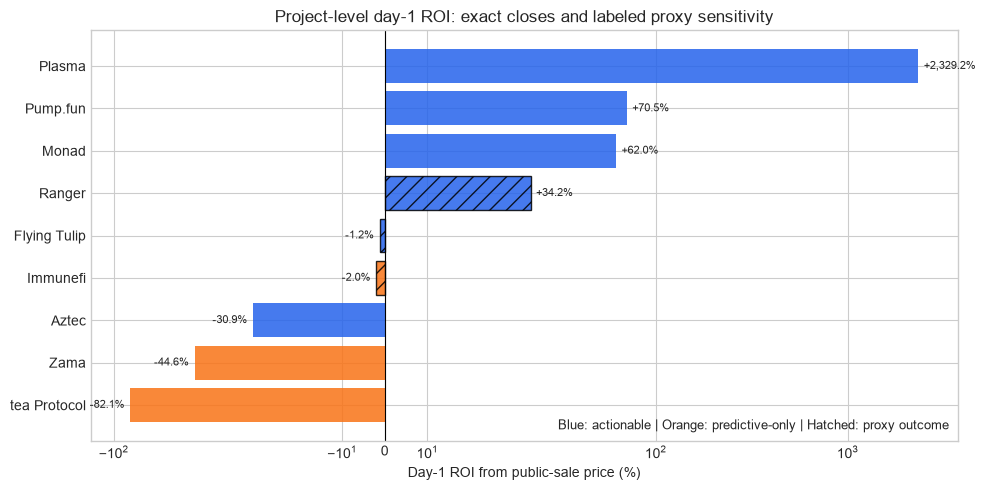

In [9]:
plot_data = project_results.dropna(subset=["day1_sensitivity_roi_pct"]).copy()
plot_data = plot_data.sort_values("day1_sensitivity_roi_pct")
colors = plot_data["pm_actionability"].map(
    {"actionable": "#2563eb", "predictive_only": "#f97316"}
)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(
    plot_data["project"],
    plot_data["day1_sensitivity_roi_pct"],
    color=colors,
    alpha=0.85,
)
for bar, quality in zip(bars, plot_data["day1_sensitivity_quality"]):
    if quality == "proxy":
        bar.set_hatch("//")
        bar.set_edgecolor("black")

ax.set_xscale("symlog", linthresh=50)
for bar, value in zip(bars, plot_data["day1_sensitivity_roi_pct"]):
    ax.annotate(
        f"{value:+,.1f}%",
        (value, bar.get_y() + bar.get_height() / 2),
        xytext=(4 if value >= 0 else -4, 0),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=8,
    )

ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Day-1 ROI from public-sale price (%)")
ax.set_ylabel("")
ax.set_title("Project-level day-1 ROI: exact closes and labeled proxy sensitivity")
ax.text(
    0.99,
    0.02,
    "Blue: actionable | Orange: predictive-only | Hatched: proxy outcome",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
)
plt.tight_layout()
plt.show()


## 8. Polymarket signal analysis

The intended main feature cannot be calculated for any row because every exact point-in-time probability and snapshot timestamp is missing. Resolved FDV brackets are outcomes and are not substituted as features.

The table below is a proxy-only diagnostic. It has unknown snapshot timing and therefore cannot establish an actionable edge.


In [10]:
proxy_signal = analysis.loc[
    analysis["pm_proxy_threshold_count"].gt(0),
    [
        "project",
        "pm_actionability",
        "sale_fdv_usd",
        "pm_proxy_median_floor_fdv_usd",
        "pm_proxy_median_floor_multiple",
        "pm_total_volume_usd",
        "pm_resolved_fdv_lower_usd",
        "pm_resolved_fdv_upper_usd",
        "day1_sensitivity_roi_pct",
        "day1_sensitivity_quality",
        "pm_probs_quality",
    ],
].copy()

proxy_signal["sale_fdv_usd_m"] = proxy_signal["sale_fdv_usd"] / 1e6
proxy_signal["proxy_median_floor_fdv_usd_m"] = (
    proxy_signal["pm_proxy_median_floor_fdv_usd"] / 1e6
)
proxy_signal["pm_volume_usd_m"] = proxy_signal["pm_total_volume_usd"] / 1e6
display(
    proxy_signal[
        [
            "project",
            "pm_actionability",
            "sale_fdv_usd_m",
            "proxy_median_floor_fdv_usd_m",
            "pm_proxy_median_floor_multiple",
            "pm_volume_usd_m",
            "day1_sensitivity_roi_pct",
            "day1_sensitivity_quality",
        ]
    ].round(2)
)

print(
    "Exact actionable valuation-gap rows:",
    int(analysis["pm_actionable_signal_available"].sum()),
)
print(
    "Usable proxy gap + actionable + observed day-1 outcome rows:",
    int(
        (
            analysis["pm_actionability"].eq("actionable")
            & analysis["pm_proxy_median_floor_fdv_usd"].notna()
            & analysis["day1_sensitivity_roi_pct"].notna()
        ).sum()
    ),
)


,project,pm_actionability,sale_fdv_usd_m,proxy_median_floor_fdv_usd_m,pm_proxy_median_floor_multiple,pm_volume_usd_m,day1_sensitivity_roi_pct,day1_sensitivity_quality
3,tea Protocol,predictive_only,50.00,40.0,0.80,0.24,-82.06,exact
5,Solstice,actionable,130.00,100.0,0.77,2.21,NaN,missing
9,Ranger,actionable,15.38,30.0,1.95,0.88,34.16,proxy


Exact actionable valuation-gap rows: 0
Usable proxy gap + actionable + observed day-1 outcome rows: 1


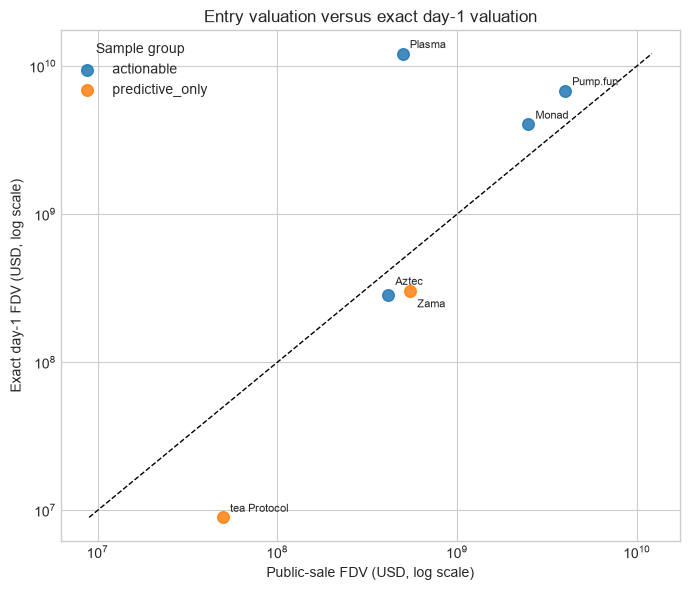

In [11]:
exact_fdv = analysis.dropna(
    subset=["sale_fdv_usd", "day1_exact_fdv_usd"]
).copy()

fig, ax = plt.subplots(figsize=(7, 6))
label_offsets = {"Aztec": (5, 7), "Zama": (5, -12)}
for group, group_data in exact_fdv.groupby("pm_actionability"):
    ax.scatter(
        group_data["sale_fdv_usd"],
        group_data["day1_exact_fdv_usd"],
        s=70,
        label=group,
        alpha=0.85,
    )
    for _, row in group_data.iterrows():
        ax.annotate(
            row["project"],
            (row["sale_fdv_usd"], row["day1_exact_fdv_usd"]),
            xytext=label_offsets.get(row["project"], (5, 4)),
            textcoords="offset points",
            fontsize=8,
        )

minimum = min(exact_fdv["sale_fdv_usd"].min(), exact_fdv["day1_exact_fdv_usd"].min())
maximum = max(exact_fdv["sale_fdv_usd"].max(), exact_fdv["day1_exact_fdv_usd"].max())
ax.plot([minimum, maximum], [minimum, maximum], color="black", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Public-sale FDV (USD, log scale)")
ax.set_ylabel("Exact day-1 FDV (USD, log scale)")
ax.set_title("Entry valuation versus exact day-1 valuation")
ax.legend(title="Sample group")
plt.tight_layout()
plt.show()


## 9. Unlock and vesting analysis

Unlock and vesting are interpreted as controls, not optimized into a score. In this sample, nearly every project has 100% TGE unlock. The only 50% unlock case lacks a day-1 outcome, so the pilot cannot estimate an unlock effect.


In [12]:
unlock_view = analysis[
    [
        "project",
        "pm_actionability",
        "tge_unlock_pct",
        "vesting",
        "day1_exact_roi_pct",
        "day1_sensitivity_roi_pct",
        "day1_sensitivity_quality",
    ]
].sort_values(["tge_unlock_pct", "project"])
display(unlock_view)

observed_actionable = filter_actionable(analysis).dropna(
    subset=["day1_sensitivity_roi_pct"]
)
print(
    "Unlock percentages among actionable projects with any day-1 outcome:",
    sorted(observed_actionable["tge_unlock_pct"].unique().tolist()),
)


,project,pm_actionability,tge_unlock_pct,vesting,day1_exact_roi_pct,day1_sensitivity_roi_pct,day1_sensitivity_quality
5,Solstice,actionable,50,remaining 50% linear over 3 months,NaN,NaN,missing
8,Aztec,actionable,100,none for public-sale allocation,-30.916867,-30.916867,exact
4,Flying Tulip,actionable,100,100% unlocked; tokens embedded in Perpetual PU...,NaN,-1.210000,proxy
7,Immunefi,predictive_only,100,none for public-sale allocation,NaN,-2.019447,proxy
2,Monad,actionable,100,none for public-sale allocation,62.000000,62.000000,exact
1,Plasma,actionable,100,non-US: fully unlocked; US participants: 12-mo...,2329.200000,2329.200000,exact
0,Pump.fun,actionable,100,none for public-sale tokens,70.500000,70.500000,exact
9,Ranger,actionable,100,none reported for public-sale allocation,NaN,34.159667,proxy
6,Zama,predictive_only,100,none for public-sale allocation,-44.600000,-44.600000,exact
3,tea Protocol,predictive_only,100,none for public-sale allocation,-82.062000,-82.062000,exact


Unlock percentages among actionable projects with any day-1 outcome: [100]


## 10. Polymarket volume interpretation

Volume is shown as context rather than converted into a fitted weight. With only four actionable projects having exact day-1 outcomes, any correlation is unstable and should not become a rule.


In [13]:
actionable_exact = filter_actionable(analysis).dropna(
    subset=["day1_exact_roi_pct"]
).copy()
volume_rank_correlation = actionable_exact["pm_total_volume_usd"].rank().corr(
    actionable_exact["day1_exact_roi_pct"].rank()
)

display(
    actionable_exact[
        ["project", "pm_total_volume_usd", "day1_exact_roi_pct"]
    ].sort_values("pm_total_volume_usd")
)
print(
    f"Rank correlation between PM volume and exact day-1 ROI: "
    f"{volume_rank_correlation:.2f} (n={len(actionable_exact)}; descriptive only)"
)


,project,pm_total_volume_usd,day1_exact_roi_pct
1,Plasma,818975,2329.200000
8,Aztec,1341311,-30.916867
0,Pump.fun,2049788,70.500000
2,Monad,53790537,62.000000


Rank correlation between PM volume and exact day-1 ROI: -0.40 (n=4; descriptive only)


## 11. Sensitivity to proxies and missing data

The exact-only view is the primary outcome summary. The sensitivity view adds proxy day-high/intraday values for Flying Tulip and Ranger. Solstice remains missing.


In [14]:
actionable = filter_actionable(analysis)
exact_actionable = actionable.dropna(subset=["day1_exact_roi_pct"])
sensitivity_actionable = actionable.dropna(subset=["day1_sensitivity_roi_pct"])

sensitivity_summary = pd.DataFrame(
    [
        {
            "view": "Exact day-1 closes only",
            "n": len(exact_actionable),
            "positive_n": int(exact_actionable["day1_exact_roi_pct"].gt(0).sum()),
            "mean_roi_pct": exact_actionable["day1_exact_roi_pct"].mean(),
            "median_roi_pct": exact_actionable["day1_exact_roi_pct"].median(),
            "min_roi_pct": exact_actionable["day1_exact_roi_pct"].min(),
            "max_roi_pct": exact_actionable["day1_exact_roi_pct"].max(),
        },
        {
            "view": "Exact + labeled proxy sensitivity",
            "n": len(sensitivity_actionable),
            "positive_n": int(
                sensitivity_actionable["day1_sensitivity_roi_pct"].gt(0).sum()
            ),
            "mean_roi_pct": sensitivity_actionable[
                "day1_sensitivity_roi_pct"
            ].mean(),
            "median_roi_pct": sensitivity_actionable[
                "day1_sensitivity_roi_pct"
            ].median(),
            "min_roi_pct": sensitivity_actionable[
                "day1_sensitivity_roi_pct"
            ].min(),
            "max_roi_pct": sensitivity_actionable[
                "day1_sensitivity_roi_pct"
            ].max(),
        },
    ]
)
display(sensitivity_summary.round(2))

without_plasma = exact_actionable.loc[
    exact_actionable["project"].ne("Plasma"), "day1_exact_roi_pct"
]
print(
    "Exact actionable ROI excluding Plasma: "
    f"mean {without_plasma.mean():.2f}%, median {without_plasma.median():.2f}% "
    f"(n={len(without_plasma)})"
)


,view,n,positive_n,mean_roi_pct,median_roi_pct,min_roi_pct,max_roi_pct
0,Exact day-1 closes only,4,3,607.70,66.25,-30.92,2329.2
1,Exact + labeled proxy sensitivity,6,4,410.62,48.08,-30.92,2329.2


Exact actionable ROI excluding Plasma: mean 33.86%, median 62.00% (n=3)


## 12. Processed analysis table

The processed file preserves source fields needed for interpretation and adds only derived values with explicit exact/proxy naming.


In [15]:
processed_columns = [
    "project",
    "token",
    "sale_platform",
    "sale_start_utc",
    "sale_close_utc",
    "sale_close_quality",
    "sale_price_usd",
    "sale_fdv_usd",
    "sale_price_method",
    "tge_time_utc",
    "tge_time_quality",
    "tge_unlock_pct",
    "vesting",
    "pm_market_open_time_utc",
    "pm_actionability",
    "pm_pre_tge_snapshot_time_utc",
    "pm_pre_tge_probs",
    "pm_probs_proxy",
    "pm_probs_quality",
    "pm_total_volume_usd",
    "pm_resolved_fdv_lower_usd",
    "pm_resolved_fdv_upper_usd",
    "price_1d_usd",
    "price_1d_proxy_usd",
    "price_1d_proxy_method",
    "total_supply",
    "derived_roi_1d_pct",
    "derived_fdv_1d_usd",
    "derived_roi_7d_pct",
    "derived_fdv_7d_usd",
    "derived_roi_30d_pct",
    "derived_fdv_30d_usd",
    "derived_roi_90d_pct",
    "derived_fdv_90d_usd",
    "day1_exact_roi_pct",
    "day1_exact_fdv_usd",
    "day1_sensitivity_roi_pct",
    "day1_sensitivity_fdv_usd",
    "day1_sensitivity_quality",
    "pm_exact_snapshot_available",
    "pm_actionable_signal_available",
    "pm_proxy_threshold_count",
    "pm_proxy_median_floor_fdv_usd",
    "pm_proxy_median_floor_multiple",
]

PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
analysis[processed_columns].to_csv(PROCESSED_PATH, index=False)
print(f"Saved {len(analysis)} rows × {len(processed_columns)} columns to {PROCESSED_PATH.relative_to(ROOT)}")


Saved 10 rows × 44 columns to data/processed/tge_polymarket_backtest_v0.csv


## 13. Key findings and limitations

1. **Polymarket prediction quality:** not testable credibly. Exact historical probabilities and snapshot timestamps are absent for all ten projects. Resolution brackets confirm outcomes, not what the market predicted beforehand.
2. **Actionable valuation-gap hypothesis:** not testable in the strict sample. There are zero actionable rows with an exact pre-sale Polymarket valuation signal.
3. **Outcome evidence:** four actionable projects have exact day-1 closes. Three are positive, with a median ROI of **+66.25%**. The **+607.70%** mean is dominated by Plasma at **+2,329.2%**. Excluding Plasma leaves three observations with a mean of **+33.86%**.
4. **Proxy sensitivity:** including two clearly labeled proxy outcomes gives six actionable observations, four positive, with a median ROI of **+48.08%**. This is descriptive outcome evidence, not evidence that the Polymarket gap caused or predicted the returns.
5. **Controls:** Polymarket volume shows no reliable pattern at this sample size. Unlock cannot be tested because all actionable projects with observed day-1 outcomes have 100% unlock.
6. **Benchmarks:** BTC/ETH fields are empty, so excess returns remain an explicit enrichment task.
7. **Selection risk:** ten hand-collected projects may omit failed or less visible sales, creating survivorship or selection bias.

No ENTER/WATCH/SKIP rule is justified from the current data.


## 14. Conclusion and next data-collection priorities

### Conclusion: MAYBE

The public-sale outcomes are interesting enough to justify a larger, better-instrumented dataset, but the defining explanatory variable is missing. This pilot supports **collecting more point-in-time data**, not deploying a TGE strategy.

Highest-value next data:

1. Exact Polymarket CLOB threshold probabilities captured immediately before each public-sale close.
2. Exact snapshot timestamps and market identifiers, with an auditable decision cutoff.
3. A larger, systematic universe that includes unattractive and failed public sales.
4. Exact horizon-aligned day-1 close prices and FDV, separate from intraday highs.
5. Complete unlock and vesting mechanics at TGE.
6. BTC and ETH horizon returns for excess-return calculations.
7. Historical social metrics only after the valuation signal and outcomes are reliable.

A future backtest should require enough actionable rows with exact signals to compare signal ranks against exact day-1 ROI without relying on a single outlier.
